In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
from matplotlib import rcParams
import plotting_functions

In [2]:
pwd()

'/Users/edwin/Documents/1-work_Riverside/John_Barton/2-Flu/New_Data/code/notebooks/Figs_production'

In [2]:
# Load Data
df_pop_full= pd.read_csv('data_Figs/Fig_Clades_Evolution/clade_evolution_H3N2_HA_NXT.csv');
df_pop_past= pd.read_csv('data_Figs/Fig_Clades_Evolution/clade_evolution_H3N2_HA_t0_2014-06-01.csv');
df_pop_past = df_pop_past[df_pop_past['Date'] > '2011-08-01']
df_pop_0_t90= pd.read_csv('data_Figs/Fig_Clades_Evolution/3m_forecast_clade_config_H3N2_HA_t0_2014-06-01_tf_2014-08-31.csv');
df_pop_0_t180= pd.read_csv('data_Figs/Fig_Clades_Evolution/6m_forecast_clade_config_H3N2_HA_t0_2014-06-01_tf_2014-11-29.csv');
df_pop_0_t270= pd.read_csv('data_Figs/Fig_Clades_Evolution/9m_forecast_clade_config_H3N2_HA_t0_2014-06-01_tf_2015-02-27.csv');
df_pop_0_t360= pd.read_csv('data_Figs/Fig_Clades_Evolution/12m_forecast_clade_config_H3N2_HA_t0_2014-06-01_tf_2015-05-28.csv');

In [3]:
# Filter Data

filtered_df = df_pop_past[df_pop_past['Date'] > '2011-08-01']
all_clades = sorted(filtered_df['clade'].unique())  
clade_color_map = plotting_functions.get_clade_color_map(all_clades)

df_pop_full['Date'] = pd.to_datetime(df_pop_full['Date'])  # Make sure 'Date' is datetime
df_pop_full = df_pop_full[(df_pop_full['Date'] > '2011-08-01') & (df_pop_full['Date'] < '2015-05-29')]

# Filter clades with total frequency > 1
clade_freq_sum = df_pop_full.groupby('clade')['frequency'].sum()
clades_over_1 = clade_freq_sum[clade_freq_sum > 1.0].index
df_pop_full_filt = df_pop_full[df_pop_full['clade'].isin(clades_over_1)]
#past
df_pop_past_filt = df_pop_past[df_pop_past['clade'].isin(clades_over_1)]
#90
df_pop_0_t90_filt = df_pop_0_t90[df_pop_0_t90['clade'].isin(clades_over_1)]
#180
df_pop_0_t180_filt = df_pop_0_t180[df_pop_0_t180['clade'].isin(clades_over_1)]
#270
df_pop_0_t270_filt = df_pop_0_t270[df_pop_0_t270['clade'].isin(clades_over_1)]
#360
df_pop_0_t360_filt = df_pop_0_t360[df_pop_0_t360['clade'].isin(clades_over_1)]

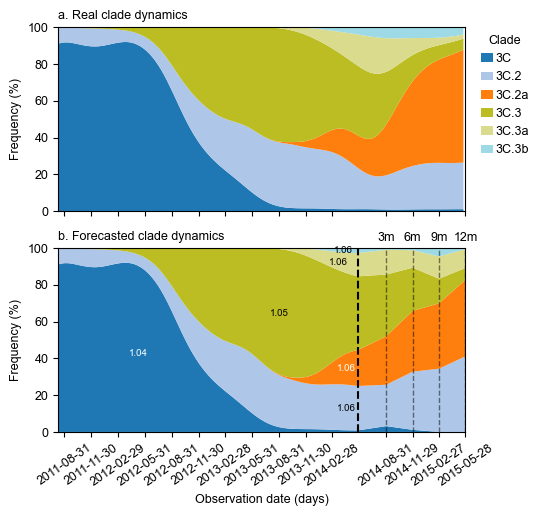

In [12]:
# Create shared figure and axes
fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, figsize=plotting_functions.get_figsize("square"), sharex=True, gridspec_kw={'height_ratios': [1, 1],'hspace': 0.2 }
)

# Plot into existing axes
plotting_functions.plot_clade_dynamics_with_fitness(
    df_pop_full_filt, clade_color_map,
    title="a. Real clade dynamics", 
    ax=ax_top
)

plotting_functions.plot_clade_dynamics_with_four_forecasts(
    df_past=df_pop_past_filt,
    df_forecast_rm=df_pop_0_t90_filt,
    df_forecast1=df_pop_0_t180_filt,
    df_forecast2=df_pop_0_t270_filt,
    df_forecast3=df_pop_0_t360_filt,
    clade_color_map=clade_color_map,
    title="b. Forecasted clade dynamics",
    ax=ax_bottom
)

# Hide x-axis labels from top
ax_top.set_xlabel('')
xlim_bottom = ax_bottom.get_xlim()
ax_top.set_xlim(xlim_bottom)
plt.show()
fig.savefig('clades_forecasting_t0_2014-06-01.pdf',format="pdf", bbox_inches='tight',dpi=300)